In [1]:
import os
import random
from pathlib import Path

# Data Manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Image Processing
from PIL import Image

# Machine Learning
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# TorchVision
from torchvision import transforms

# Albumentations
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Model Library
import timm

# Progress Bar
from tqdm.auto import tqdm

In [9]:
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print(TRAIN_DIR)
print(TEST_DIR)

..\data\train
..\data\test


In [2]:
print("PyTorch :", torch.__version__)
print("Torch CUDA :", torch.cuda.is_available())
print("TIMM :", timm.__version__)
print("Albumentations :", A.__version__)

PyTorch : 2.12.1+cpu
Torch CUDA : False
TIMM : 1.0.27
Albumentations : 2.0.8


In [31]:
class CFG:
    SEED = 42
    IMAGE_SIZE = 224
    BATCH_SIZE = 8
    EPOCHS = 15
    LR = 1e-3
    NUM_CLASSES = 3
    MODEL_NAME = "efficientnet_b0"
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(CFG.SEED)

In [7]:
print("Device :", CFG.DEVICE)
print("Model  :", CFG.MODEL_NAME)
print("Image Size :", CFG.IMAGE_SIZE)
print("Batch Size :", CFG.BATCH_SIZE)

Device : cpu
Model  : efficientnet_b0
Image Size : 224
Batch Size : 16


In [10]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
valid_df = pd.read_csv(DATA_DIR / "valid.csv")

print(f"Train samples      : {len(train_df):,}")
print(f"Validation samples : {len(valid_df):,}")

Train samples      : 21,220
Validation samples : 5,305


In [11]:
display(train_df.head())

display(valid_df.head())

,filepath,filename,label,class_name
0,..\data\train\0_Recyclable\R_932.jpg,R_932.jpg,0,0_Recyclable
1,..\data\train\2_Organic\O_2843.jpg,O_2843.jpg,2,2_Organic
2,..\data\train\1_Electronic\pcb_133.jpg,pcb_133.jpg,1,1_Electronic
3,..\data\train\0_Recyclable\R_4120.jpg,R_4120.jpg,0,0_Recyclable
4,..\data\train\0_Recyclable\R_569.jpg,R_569.jpg,0,0_Recyclable


,filepath,filename,label,class_name
0,..\data\train\2_Organic\O_8471.jpg,O_8471.jpg,2,2_Organic
1,..\data\train\1_Electronic\Player_41.jpg,Player_41.jpg,1,1_Electronic
2,..\data\train\0_Recyclable\R_5835.jpg,R_5835.jpg,0,0_Recyclable
3,..\data\train\2_Organic\O_3885.jpg,O_3885.jpg,2,2_Organic
4,..\data\train\1_Electronic\battery_256.jpg,battery_256.jpg,1,1_Electronic


In [12]:
print(train_df["label"].value_counts().sort_index())

label
0     7999
1     3167
2    10054
Name: count, dtype: int64


In [13]:
print(valid_df["label"].value_counts().sort_index())

label
0    2000
1     792
2    2513
Name: count, dtype: int64


In [14]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(CFG.DEVICE)

print(class_weights)

tensor([0.8843, 2.2334, 0.7035])


In [15]:
for i in range(5):

    path = Path(train_df.loc[i, "filepath"])

    print(path.exists(), path)

True ..\data\train\0_Recyclable\R_932.jpg
True ..\data\train\2_Organic\O_2843.jpg
True ..\data\train\1_Electronic\pcb_133.jpg
True ..\data\train\0_Recyclable\R_4120.jpg
True ..\data\train\0_Recyclable\R_569.jpg


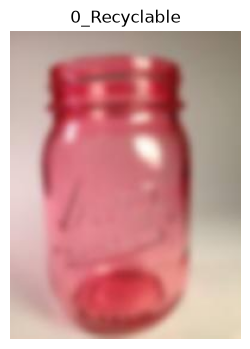

In [16]:
sample = train_df.sample(1, random_state=CFG.SEED).iloc[0]

image = Image.open(sample["filepath"]).convert("RGB")

plt.figure(figsize=(4,4))
plt.imshow(image)
plt.title(sample["class_name"])
plt.axis("off")

plt.show()

In [17]:
train_transform = A.Compose([
    A.Resize(CFG.IMAGE_SIZE, CFG.IMAGE_SIZE),

    A.HorizontalFlip(p=0.5),

    A.Rotate(
        limit=15,
        p=0.5
    ),

    A.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1,
        p=0.5
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])


valid_transform = A.Compose([
    A.Resize(CFG.IMAGE_SIZE, CFG.IMAGE_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

In [32]:
class WasteDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)

        self.transform = transform


    def __len__(self):

        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(path).convert("RGB")

        image = image.resize(
            (CFG.IMAGE_SIZE, CFG.IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        image = np.array(image)

        image = self.transform(image=image)["image"]

        if self.transform:

            image = self.transform(image=image)["image"]

        label = int(row["label"])

        return image, label

In [19]:
train_dataset = WasteDataset(
    train_df,
    transform=train_transform
)

valid_dataset = WasteDataset(
    valid_df,
    transform=valid_transform
)

print(len(train_dataset))
print(len(valid_dataset))

21220
5305


In [20]:
train_loader = DataLoader(
    train_dataset,
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [21]:
images, labels = next(iter(train_loader))

print("Image Shape :", images.shape)
print("Label Shape :", labels.shape)
print("Label :", labels[:10])

Image Shape : torch.Size([16, 3, 224, 224])
Label Shape : torch.Size([16])
Label : tensor([2, 1, 2, 2, 1, 0, 1, 2, 0, 0])


In [22]:
model = timm.create_model(
    CFG.MODEL_NAME,
    pretrained=True,
    num_classes=CFG.NUM_CLASSES
)

model = model.to(CFG.DEVICE)

print(model)

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

d:\poetri\.venv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aeipr\.cache\huggingface\hub\models--timm--efficientnet_b0.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bi

In [23]:
# Loss Function

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [24]:
# Optimizer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG.LR,
    weight_decay=1e-4
)

In [25]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CFG.EPOCHS
)

In [26]:
print(model)

print("\nLoss :", criterion)
print("\nOptimizer :", optimizer)
print("\nScheduler :", scheduler)

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bi

In [27]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / len(loader)

    return epoch_loss

In [29]:
@torch.no_grad()
def valid_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    progress_bar = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / len(loader)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    return epoch_loss, macro_f1, all_labels, all_preds

In [33]:
best_f1 = 0.0

history = {
    "train_loss": [],
    "valid_loss": [],
    "macro_f1": []
}

for epoch in range(CFG.EPOCHS):

    print(f"\nEpoch {epoch+1}/{CFG.EPOCHS}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        CFG.DEVICE
    )

    valid_loss, macro_f1, y_true, y_pred = valid_one_epoch(
        model,
        valid_loader,
        criterion,
        CFG.DEVICE
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["valid_loss"].append(valid_loss)
    history["macro_f1"].append(macro_f1)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Valid Loss : {valid_loss:.4f}")
    print(f"Macro F1   : {macro_f1:.4f}")

    if macro_f1 > best_f1:

        best_f1 = macro_f1

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

        print("✅ Best Model Saved")

print("\nTraining Finished")
print(f"Best Macro F1 : {best_f1:.4f}")


Epoch 1/15


Training:   0%|          | 0/1327 [00:00<?, ?it/s]

KeyboardInterrupt: 